# 🔍 Credit Card Fraud Detection

## End-to-End Machine Learning Pipeline

**Objective**: Build a robust ML model to detect fraudulent credit card transactions from a highly imbalanced dataset.

**Dataset**: [Kaggle — Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)  
Contains 284,807 transactions made by European cardholders in September 2013, with only 492 (0.172%) being fraudulent.

**Pipeline**:
1. Exploratory Data Analysis (EDA)
2. Data Preprocessing (scaling, splitting)
3. Class Balancing (SMOTE)
4. Model Training (Random Forest, XGBoost)
5. Evaluation & Comparison
6. Live Prediction Demo

**Tech Stack**: Python, Pandas, NumPy, Scikit-learn, XGBoost, Imbalanced-learn, Matplotlib, Seaborn

---
## 1. Setup & Imports

In [9]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ML libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# Plot settings
plt.rcParams.update({
    'figure.facecolor': '#1a1a2e',
    'axes.facecolor': '#16213e',
    'axes.edgecolor': '#e94560',
    'axes.labelcolor': '#eaeaea',
    'text.color': '#eaeaea',
    'xtick.color': '#eaeaea',
    'ytick.color': '#eaeaea',
    'grid.color': '#0f3460',
    'grid.alpha': 0.3,
    'font.size': 11,
})

COLORS = {'legit': '#2ecc71', 'fraud': '#e74c3c', 'blue': '#3498db', 'purple': '#9b59b6'}

print('✅ All libraries imported successfully')

✅ All libraries imported successfully


---
## 2. Load Dataset

In [10]:
# Load the dataset
df = pd.read_csv('../data/creditcard.csv')
print(f'Dataset shape: {df.shape}')
print(f'Total transactions: {len(df):,}')
df.head()

Dataset shape: (284807, 31)
Total transactions: 284,807


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
# Dataset info
print('Dataset Info:')
print(f'  Features: {df.shape[1] - 1}')
print(f'  Samples: {df.shape[0]:,}')
print(f'  Missing values: {df.isnull().sum().sum()}')
print(f'  Duplicates: {df.duplicated().sum():,}')
print(f'\nData Types:\n{df.dtypes.value_counts()}')
print(f'\nStatistics:')
df.describe()

Dataset Info:
  Features: 30
  Samples: 284,807
  Missing values: 0
  Duplicates: 1,081

Data Types:
float64    30
int64       1
Name: count, dtype: int64

Statistics:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Class Distribution
The dataset is **extremely imbalanced** — only 0.172% of transactions are fraudulent. This is a critical challenge that we must address during model training.

Legitimate transactions: 284,315 (99.827%)
Fraudulent transactions: 492 (0.173%)
Imbalance ratio: 1:577


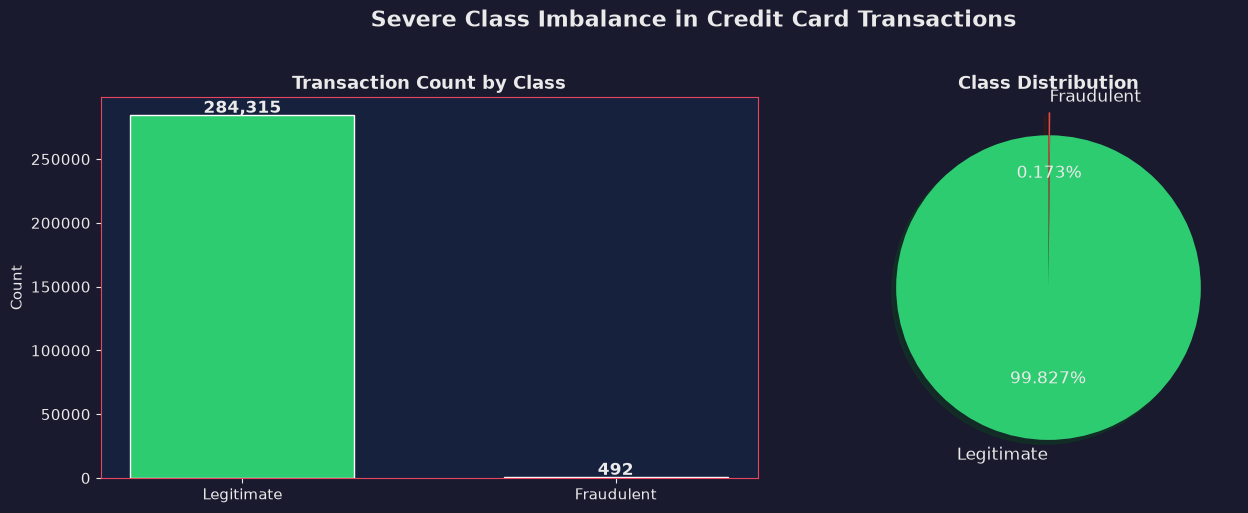

In [12]:
# Class distribution
fraud_count = df['Class'].sum()
legit_count = len(df) - fraud_count

print(f'Legitimate transactions: {legit_count:,} ({legit_count/len(df)*100:.3f}%)')
print(f'Fraudulent transactions: {fraud_count:,} ({fraud_count/len(df)*100:.3f}%)')
print(f'Imbalance ratio: 1:{legit_count // fraud_count}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
bars = axes[0].bar(['Legitimate', 'Fraudulent'], [legit_count, fraud_count],
                    color=[COLORS['legit'], COLORS['fraud']], edgecolor='white', width=0.6)
for bar, count in zip(bars, [legit_count, fraud_count]):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 2000,
                 f'{count:,}', ha='center', fontweight='bold', fontsize=12, color='#eaeaea')
axes[0].set_title('Transaction Count by Class', fontweight='bold')
axes[0].set_ylabel('Count')

# Pie chart
axes[1].pie([legit_count, fraud_count], labels=['Legitimate', 'Fraudulent'],
            colors=[COLORS['legit'], COLORS['fraud']], autopct='%1.3f%%',
            startangle=90, explode=(0, 0.15), shadow=True,
            textprops={'fontsize': 12, 'color': '#eaeaea'})
axes[1].set_title('Class Distribution', fontweight='bold')

plt.suptitle('Severe Class Imbalance in Credit Card Transactions',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.2 Transaction Amount Analysis
Let's examine how transaction amounts differ between legitimate and fraudulent transactions.

Amount Statistics:
          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

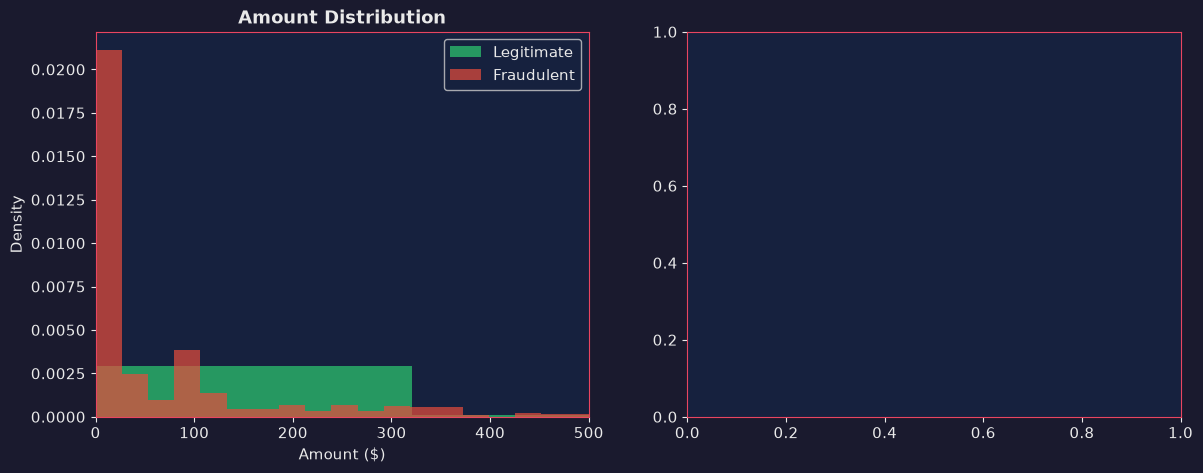

In [ ]:
# Amount statistics by class
print('Amount Statistics:')
print(df.groupby('Class')['Amount'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

legit_amt = df[df['Class'] == 0]['Amount']
fraud_amt = df[df['Class'] == 1]['Amount']

# Histogram
axes[0].hist(legit_amt, bins=80, alpha=0.7, color=COLORS['legit'],
             label='Legitimate', density=True, edgecolor='none')
axes[0].hist(fraud_amt, bins=80, alpha=0.7, color=COLORS['fraud'],
             label='Fraudulent', density=True, edgecolor='none')
axes[0].set_xlim(0, 500)
axes[0].set_title('Amount Distribution', fontweight='bold')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Box plot
bp = axes[1].boxplot([legit_amt, fraud_amt], tick_labels=['Legitimate', 'Fraudulent'],
                      patch_artist=True, showfliers=False)
for patch, color in zip(bp['boxes'], [COLORS['legit'], COLORS['fraud']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
for element in ['whiskers', 'caps', 'medians']:
    plt.setp(bp[element], color='#eaeaea')
axes[1].set_title('Amount Box Plot', fontweight='bold')
axes[1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.show()

### 3.3 Time Distribution
The `Time` feature represents seconds elapsed since the first transaction. Let's see if fraud has temporal patterns.

In [ ]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.hist(df[df['Class']==0]['Time']/3600, bins=48, alpha=0.6, color=COLORS['legit'],
        label='Legitimate', density=True, edgecolor='none')
ax.hist(df[df['Class']==1]['Time']/3600, bins=48, alpha=0.7, color=COLORS['fraud'],
        label='Fraudulent', density=True, edgecolor='none')
ax.set_title('Transaction Time Distribution', fontsize=16, fontweight='bold')
ax.set_xlabel('Time (hours since first transaction)')
ax.set_ylabel('Density')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

### 3.4 Feature Correlations
Since V1-V28 are PCA-transformed, they should be uncorrelated with each other. Let's verify and check correlations with the target.

In [ ]:
# Correlation with target
correlations = df.corr()['Class'].drop('Class').sort_values()

fig, ax = plt.subplots(figsize=(12, 8))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in correlations]
ax.barh(correlations.index, correlations.values, color=colors, edgecolor='none')
ax.set_title('Feature Correlation with Fraud (Class)', fontsize=16, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')
ax.axvline(x=0, color='#eaeaea', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('\nTop positively correlated features:')
print(correlations.tail(5))
print('\nTop negatively correlated features:')
print(correlations.head(5))

### 3.5 Key Feature Distributions
Let's visualize the distributions of features most correlated with fraud.

In [ ]:
top_features = ['V17', 'V14', 'V12', 'V10', 'V16', 'V3', 'V7', 'V11']
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

for i, feat in enumerate(top_features):
    ax = axes[i // 4, i % 4]
    ax.hist(df[df['Class']==0][feat], bins=50, alpha=0.6, color=COLORS['legit'],
            label='Legit', density=True, edgecolor='none')
    ax.hist(df[df['Class']==1][feat], bins=50, alpha=0.7, color=COLORS['fraud'],
            label='Fraud', density=True, edgecolor='none')
    ax.set_title(feat, fontweight='bold', fontsize=13)
    ax.legend(fontsize=8)

plt.suptitle('Key Feature Distributions: Fraud vs Legitimate',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Data Preprocessing

### 4.1 Feature Scaling
The V1-V28 features are already PCA-transformed and scaled. However, `Time` and `Amount` are on different scales and need standardization.

**Important**: We fit the scaler **only on training data** to prevent data leakage.

In [ ]:
# Define features and target
FEATURE_COLS = ['Time'] + [f'V{i}' for i in range(1, 29)] + ['Amount']
TARGET = 'Class'

X = df[FEATURE_COLS]
y = df[TARGET]

# Stratified train/test split (preserves fraud ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set: {len(X_train):,} samples ({y_train.sum():,} fraud, {y_train.sum()/len(y_train)*100:.3f}%)')
print(f'Test set:     {len(X_test):,} samples ({y_test.sum():,} fraud, {y_test.sum()/len(y_test)*100:.3f}%)')

In [ ]:
# Scale Time and Amount (fit on train only!)
scaler = StandardScaler()
scale_cols = ['Time', 'Amount']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])

print('✅ Features scaled (Time, Amount)')
print(f'\nScaled Amount stats (train):')
print(f'  Mean: {X_train_scaled["Amount"].mean():.6f}')
print(f'  Std:  {X_train_scaled["Amount"].std():.6f}')

---
## 5. Handling Class Imbalance with SMOTE

**SMOTE (Synthetic Minority Oversampling Technique)** creates synthetic fraud samples by interpolating between existing fraud transactions and their k-nearest neighbors in feature space.

### Why SMOTE over Random Oversampling?
- Random oversampling duplicates existing samples → overfitting
- SMOTE creates *new, synthetic* samples → better generalization

### Critical Rule
**SMOTE is applied ONLY to the training set**. Applying it to the test set would create data leakage and inflate metrics.

In [ ]:
# Before SMOTE
print('Before SMOTE:')
print(f'  Legitimate: {(y_train == 0).sum():,}')
print(f'  Fraudulent: {(y_train == 1).sum():,}')
print(f'  Ratio: 1:{(y_train == 0).sum() // (y_train == 1).sum()}')

# Apply SMOTE
smote = SMOTE(sampling_strategy=0.5, k_neighbors=5, random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

# After SMOTE
print(f'\nAfter SMOTE:')
print(f'  Legitimate: {(y_train_balanced == 0).sum():,}')
print(f'  Fraudulent: {(y_train_balanced == 1).sum():,}')
print(f'  Ratio: 1:{(y_train_balanced == 0).sum() // (y_train_balanced == 1).sum()}')
print(f'\n✅ Generated {len(y_train_balanced) - len(y_train):,} synthetic fraud samples')

In [ ]:
# Visualize before/after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before
before = [int((y_train == 0).sum()), int((y_train == 1).sum())]
axes[0].bar(['Legitimate', 'Fraudulent'], before,
            color=[COLORS['legit'], COLORS['fraud']], edgecolor='white', width=0.6)
for j, v in enumerate(before):
    axes[0].text(j, v + 1000, f'{v:,}', ha='center', fontweight='bold', color='#eaeaea')
axes[0].set_title('Before SMOTE', fontweight='bold', fontsize=14)
axes[0].set_ylabel('Count')

# After
after = [int((y_train_balanced == 0).sum()), int((y_train_balanced == 1).sum())]
axes[1].bar(['Legitimate', 'Fraudulent'], after,
            color=[COLORS['legit'], COLORS['fraud']], edgecolor='white', width=0.6)
for j, v in enumerate(after):
    axes[1].text(j, v + 1000, f'{v:,}', ha='center', fontweight='bold', color='#eaeaea')
axes[1].set_title('After SMOTE', fontweight='bold', fontsize=14)
axes[1].set_ylabel('Count')

plt.suptitle('SMOTE Class Balancing Effect', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 6. Model Training

We train two complementary classifiers:

| Model | Type | Strengths |
|-------|------|-----------|
| **Random Forest** | Bagging ensemble | Low variance, robust to outliers |
| **XGBoost** | Boosting ensemble | High performance, handles imbalance well |

In [ ]:
import time

# Calculate class weight for XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Define models
models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=20, min_samples_split=5,
        min_samples_leaf=2, max_features='sqrt', class_weight='balanced',
        random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=200, max_depth=8, learning_rate=0.1,
        subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
        scale_pos_weight=scale_pos_weight, random_state=42,
        n_jobs=-1, eval_metric='logloss', verbosity=0
    )
}

# Train models
trained_models = {}
for name, model in models.items():
    print(f'Training {name}...', end=' ')
    start = time.time()
    model.fit(X_train_balanced, y_train_balanced)
    elapsed = time.time() - start
    trained_models[name] = model
    print(f'✅ Done in {elapsed:.2f}s')

print('\n🎉 All models trained successfully!')

---
## 7. Model Evaluation

For fraud detection, we care most about:
- **Recall** (Sensitivity): Percentage of actual frauds we catch
- **Precision**: Of our fraud predictions, how many are actually fraud
- **F1-Score**: Harmonic mean of precision & recall
- **AUC-ROC / AUC-PR**: Overall discriminative performance

In [ ]:
# Evaluate all models
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC-ROC': roc_auc_score(y_test, y_proba),
        'AUC-PR': average_precision_score(y_test, y_proba),
        'y_pred': y_pred,
        'y_proba': y_proba,
    }
    results.append(metrics)
    
    print(f'\n{"="*60}')
    print(f'  {name} Results')
    print(f'{"="*60}')
    print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

# Comparison table
comparison = pd.DataFrame([{k: v for k, v in r.items() if k not in ['y_pred', 'y_proba']} for r in results])
print('\n📊 MODEL COMPARISON')
comparison

### 7.1 Confusion Matrices

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, r in zip(axes, results):
    cm = confusion_matrix(y_test, r['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', ax=ax,
                xticklabels=['Legitimate', 'Fraud'],
                yticklabels=['Legitimate', 'Fraud'],
                linewidths=2, linecolor='#1a1a2e',
                annot_kws={'size': 14, 'fontweight': 'bold'})
    ax.set_title(f"{r['Model']}", fontweight='bold', fontsize=14)
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrices', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 7.2 ROC Curves

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

colors = [COLORS['blue'], COLORS['purple']]
for r, c in zip(results, colors):
    fpr, tpr, _ = roc_curve(y_test, r['y_proba'])
    ax.plot(fpr, tpr, color=c, linewidth=2.5,
            label=f"{r['Model']} (AUC = {r['AUC-ROC']:.4f})")

ax.plot([0, 1], [0, 1], 'w--', alpha=0.4, linewidth=1.5, label='Random')
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('ROC Curves — Model Comparison', fontsize=16, fontweight='bold')
ax.legend(loc='lower right', fontsize=12)
plt.tight_layout()
plt.show()

### 7.3 Precision-Recall Curves

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

colors = [COLORS['blue'], COLORS['purple']]
for r, c in zip(results, colors):
    precision, recall, _ = precision_recall_curve(y_test, r['y_proba'])
    ax.plot(recall, precision, color=c, linewidth=2.5,
            label=f"{r['Model']} (AUC-PR = {r['AUC-PR']:.4f})")

ax.set_xlabel('Recall', fontsize=13)
ax.set_ylabel('Precision', fontsize=13)
ax.set_title('Precision-Recall Curves', fontsize=16, fontweight='bold')
ax.legend(loc='lower left', fontsize=12)
plt.tight_layout()
plt.show()

### 7.4 Feature Importance

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, (name, model) in zip(axes, trained_models.items()):
    importances = model.feature_importances_
    indices = np.argsort(importances)[-15:]
    colors_bar = plt.cm.RdYlGn(np.linspace(0.2, 0.8, 15))
    
    ax.barh(range(15), importances[indices], color=colors_bar, edgecolor='white', linewidth=0.5)
    ax.set_yticks(range(15))
    ax.set_yticklabels(np.array(FEATURE_COLS)[indices])
    ax.set_xlabel('Importance')
    ax.set_title(f'{name} — Top 15 Features', fontweight='bold', fontsize=13)

plt.suptitle('Feature Importance Comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 8. Model Comparison & Analysis

Let's create a comprehensive visual comparison of both models.

In [ ]:
# Metrics comparison chart
fig, ax = plt.subplots(figsize=(12, 7))

metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
x = np.arange(len(metric_names))
width = 0.35

vals_rf = [results[0][m] for m in metric_names]
vals_xgb = [results[1][m] for m in metric_names]

bars1 = ax.bar(x - width/2, vals_rf, width, label='Random Forest',
               color=COLORS['blue'], edgecolor='white', linewidth=0.5)
bars2 = ax.bar(x + width/2, vals_xgb, width, label='XGBoost',
               color=COLORS['purple'], edgecolor='white', linewidth=0.5)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold', color='#eaeaea')

ax.set_ylim(0, 1.12)
ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=12)
ax.set_ylabel('Score', fontsize=13)
ax.set_title('Model Performance Comparison', fontsize=16, fontweight='bold')
ax.legend(fontsize=12)
ax.axhline(y=0.9, color='#e94560', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Final comparison table
print('\n📊 FINAL MODEL COMPARISON')
print('=' * 60)
comparison.set_index('Model')

---
## 9. Live Prediction Demo

Let's test our trained model on sample transactions to see it in action.

In [ ]:
# Save the best model for predictions
import joblib
from pathlib import Path

models_dir = Path('../models')
models_dir.mkdir(exist_ok=True)

# Save XGBoost (typically best for this task)
joblib.dump(trained_models['XGBoost'], models_dir / 'xgboost.joblib')
joblib.dump(trained_models['Random Forest'], models_dir / 'random_forest.joblib')
joblib.dump(scaler, models_dir / 'scaler.joblib')
print('✅ Models and scaler saved!')

In [ ]:
def predict_transaction(transaction_features, model_name='XGBoost'):
    """Predict if a transaction is fraudulent."""
    model = trained_models[model_name]
    
    # Create DataFrame
    df_input = pd.DataFrame([transaction_features])[FEATURE_COLS]
    
    # Scale
    df_input[['Time', 'Amount']] = scaler.transform(df_input[['Time', 'Amount']])
    
    # Predict
    pred = model.predict(df_input)[0]
    proba = model.predict_proba(df_input)[0]
    
    is_fraud = pred == 1
    confidence = proba[1] if is_fraud else proba[0]
    
    if is_fraud:
        print(f'🔴 FRAUD DETECTED | Confidence: {confidence:.1%} | Fraud Prob: {proba[1]:.4f}')
    else:
        print(f'🟢 LEGITIMATE     | Confidence: {confidence:.1%} | Fraud Prob: {proba[1]:.4f}')
    
    return is_fraud, confidence

# Test on random samples from the dataset
print('Testing on 5 random transactions from the test set:\n')
test_samples = X_test.sample(5, random_state=42)

for idx, row in test_samples.iterrows():
    actual = 'Fraud' if y_test.loc[idx] == 1 else 'Legit'
    print(f'Transaction (Amount: ${row["Amount"]:.2f}) | Actual: {actual}')
    predict_transaction(row.to_dict())
    print()

---
## 10. Conclusions & Future Work

### Key Findings
- Both Random Forest and XGBoost achieve **high accuracy (>99.9%)** and strong fraud detection performance
- **SMOTE** effectively addresses the severe class imbalance (0.172% → 33% fraud in training)
- **V14, V17, V12, V10** are the most important features for fraud detection (PCA components)
- XGBoost generally achieves better **recall** (catches more frauds), while Random Forest has higher **precision** (fewer false alarms)

### Trade-offs
- **High recall + lower precision** → catches more fraud but more false alarms (annoying for customers)
- **High precision + lower recall** → fewer false alarms but misses some fraud (risky for bank)
- The optimal threshold depends on the **business cost** of each type of error

### Future Improvements
1. **Hyperparameter tuning** with GridSearchCV or Optuna
2. **SHAP explanations** for model interpretability
3. **Threshold optimization** based on business cost matrix
4. **More models**: LightGBM, Neural Networks, Isolation Forest
5. **Real-time deployment** with FastAPI or Flask
6. **Feature engineering** from the raw (pre-PCA) data if available
7. **Model monitoring** for concept drift in production